# ETS Machine Learning II — Prediksi RNFL 12 Clock-Hour dari Fundus

**Tujuan:** memperkirakan ketebalan RNFL 12 sektor dari foto fundus untuk membantu analisis saraf optik. Satuan target dan metrik adalah µm. Ini proyek eksperimen, bukan alat diagnosis klinis.

Notebook ini meneruskan replikasi Chen et al. dengan empat komponen sesuai rubrik ETS: **akuisisi/wrangling data**, **augmentasi citra**, **ensemble learning**, dan **reinforcement learning berbentuk contextual-free multi-armed bandit** untuk memilih strategi akuisisi data berlabel. Evaluasi utama memakai 5-fold GroupKFold pasien. Validasi reward bandit dipisah dari fold luar sehingga label fold luar tidak dipakai untuk memilih data.

Baseline Chen: OLS, Ridge, Lasso, ElasticNet. Model ETS membandingkan Ridge, ExtraTrees, gabungan rata-rata keduanya, dan ensemble dengan augmentasi fotometrik. Kurva akuisisi membandingkan kebijakan bandit UCB1 dengan pemilihan pasien acak pada anggaran label yang sama.

Paper acuan: Chen et al., *Independent Evaluation of RETFound Foundation Model’s Performance on Optic Nerve Analysis Using Fundus Photography*, Ophthalmology Science (2025), DOI: https://doi.org/10.1016/j.xops.2025.100720.

**Batas pairing:** tanggal foto tidak tersedia; kriteria selang 6 bulan dari paper belum dapat diverifikasi. Audit pasangan dan jumlah data yang tersisih diekspor.

## 1. Input dan cara menjalankan di Kaggle

1. Buat **Kaggle Dataset** privat yang berisi `rnfl_metadata_lengkap.csv` dan folder `fundus/` dengan foto sesuai metadata. Tambahkan dataset itu melalui **Add Input** di notebook Kaggle. Tidak perlu menaruh CSV atau foto di `/kaggle/working`.
2. Opsional: tambahkan laporan OCT sesuai `oct_filename` untuk QC, dan `fundus_oct_pairs_reviewed.csv` bila pasangan foto telah diperiksa manual.
3. Opsional untuk replikasi Chen: tambahkan dataset berisi kode resmi `RETFound_official/models_vit.py` bersama folder `util/`, checkpoint **`RETFound_mae_natureCFP.pth`**, dan paket `timm` yang kompatibel. Aktifkan GPU untuk ekstraksi RETFound. [Kode resmi](https://github.com/rmaphoh/RETFound) dan [checkpoint CFP](https://huggingface.co/YukunZhou/RETFound_mae_natureCFP) harus diunggah sebagai Kaggle Input sesuai izin penggunaannya. Checkpoint OCT tidak cocok untuk foto fundus.
4. Jalankan **Run All**. Hasil CSV dan fitur tersimpan di `/kaggle/working/rnfl_ets_outputs/` dan dapat diunduh dari tab Output. Internet Kaggle tidak diperlukan setelah semua input terpasang.

**Mode tanpa RETFound:** notebook memakai fitur gambar deterministik (thumbnail abu-abu, histogram warna, statistik warna), sehingga pipeline ETS tetap dapat dijalankan hanya dengan CSV dan foto. Angka pada mode ini adalah baseline eksploratif, **bukan** hasil replikasi RETFound/Chen. `feature_source` dicatat pada output.

Foto fundus dipertahankan orientasinya. Augmentasi hanya mengubah kecerahan, kontras, dan saturasi secara ringan. Citra validasi dan target RNFL tidak diaugmentasi. Transformasi kedua dihitung untuk seluruh citra demi cache fitur, tetapi hanya baris **train** dari tiap fold yang dipakai untuk fit model.

In [1]:
from pathlib import Path
import os, re, sys, json, math, warnings, random
import numpy as np
try:
    import torch
    from torch import nn
    from torch.utils.data import Dataset, DataLoader
    from torchvision import transforms
    from torchvision.transforms import InterpolationMode
except (ImportError, RuntimeError) as exc:
    torch = None
    print("PyTorch/torchvision tidak tersedia; fitur gambar sederhana akan dipakai:", exc)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps, ImageEnhance
from IPython.display import display

SEED = 42
N_FOLDS = 5
IMAGE_SIZE = 224
BATCH_SIZE = 8
NUM_WORKERS = 2
INPUT_ROOT = Path("/kaggle/input") if Path("/kaggle/input").exists() else Path.cwd() / "input"
OUTPUT_DIR = (Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()) / "rnfl_ets_outputs"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu") if torch else None
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
sns.set_theme(style="whitegrid", context="notebook")

image_exts = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
csv_hits = sorted(INPUT_ROOT.rglob("rnfl_metadata_lengkap.csv"))
if not csv_hits:
    raise FileNotFoundError(f"Tidak menemukan rnfl_metadata_lengkap.csv di {INPUT_ROOT}. Tambahkan Kaggle Input sesuai bagian 1.")
CSV_PATH = csv_hits[0]
fundus_hits = []
for p in INPUT_ROOT.rglob("fundus"):
    if p.is_dir() and any(x.is_file() and x.suffix.lower() in image_exts for x in p.rglob("*")):
        fundus_hits.append(p)
if not fundus_hits:
    raise FileNotFoundError(f"Folder fundus berisi citra tidak ditemukan di {INPUT_ROOT}.")
FUNDUS_DIR = sorted(fundus_hits, key=lambda p: len(p.parts))[0]
oct_image_paths = [p for p in INPUT_ROOT.rglob("*") if p.is_file() and p.suffix.lower() in image_exts and p.name.lower().startswith("oct_")]
oct_image_index = {}
for p in sorted(oct_image_paths): oct_image_index.setdefault(p.name.lower(), []).append(p)
PAIR_OVERRIDE_HITS = sorted(INPUT_ROOT.rglob("fundus_oct_pairs_reviewed.csv"))
PAIR_OVERRIDE_PATH = PAIR_OVERRIDE_HITS[0] if PAIR_OVERRIDE_HITS else None
MODEL_CODE_HITS = sorted(INPUT_ROOT.rglob("models_vit.py"))
WEIGHT_HITS = sorted(p for p in INPUT_ROOT.rglob("*.pth") if "retfound" in p.name.lower() and ("cfp" in p.name.lower() or "fundus" in p.name.lower()))
print("Metadata:", CSV_PATH, "| Fundus:", FUNDUS_DIR)
print("OCT:", len(oct_image_paths), "| Pairing manual:", PAIR_OVERRIDE_PATH)
print("Kode RETFound:", MODEL_CODE_HITS[:2], "| Bobot CFP:", WEIGHT_HITS[:2])
print("Output:", OUTPUT_DIR, "| Device:", DEVICE)

Metadata: /kaggle/input/datasets/septiadiniarifta/rnfl-fundus-sectors/rnfl_metadata_lengkap.csv | Fundus: /kaggle/input/datasets/septiadiniarifta/rnfl-fundus-sectors/fundus
OCT: 0 | Pairing manual: None
Kode RETFound: [PosixPath('/kaggle/input/datasets/septiadiniarifta/retfound/RETFound_official/models_vit.py')] | Bobot CFP: [PosixPath('/kaggle/input/datasets/septiadiniarifta/retfound/RETFound_official/RETFound_mae_natureCFP.pth')]
Output: /kaggle/working/rnfl_ets_outputs | Device: cuda


## 2. Baca metadata dan audit pasangan citra-label

Setiap baris mewakili satu mata/OCT. Pasangan dibentuk dari **ID pasien + laterality**. Notebook memilih satu foto per kombinasi ID pasien + sisi mata. Kecocokan suffix OCT-fundus yang unik diprioritaskan; jika tidak ditemukan, dipilih kandidat valid pertama secara alfabetis. Foto yang sama digunakan untuk seluruh baris RNFL pada pasien-mata itu, sehingga baris tidak dikeluarkan hanya karena ada beberapa kandidat.

Paper Chen memilih pasangan foto fundus dan OCT pada mata yang sama dengan jarak tanggal paling lama 6 bulan, lalu tanggal terdekat. CSV kita tidak memiliki tanggal foto fundus, jadi hubungan tanggal belum bisa dipastikan otomatis. Gambar OCT dapat ditampilkan berdampingan dengan fundus untuk pemeriksaan manual.



In [2]:
df_raw = pd.read_csv(CSV_PATH, dtype={"patient_id": str})
df = df_raw.copy()
df["patient_id"] = df["patient_id"].astype(str).str.strip()
df["laterality"] = df["laterality"].astype(str).str.upper().str.strip()
sector_cols = [f"rnfl_clock_{i}" for i in range(12)]
missing_cols = [c for c in ["patient_id","laterality","diagnosis","fundus_filename","oct_filename",*sector_cols] if c not in df.columns]
if missing_cols:
    raise ValueError(f"Kolom CSV tidak lengkap: {missing_cols}")
df[sector_cols] = df[sector_cols].apply(pd.to_numeric, errors="coerce")
df["diagnosis"] = df["diagnosis"].astype(str).str.lower().str.strip()

# Index semua foto dengan identitas pasien dan sisi mata yang dibaca dari nama file fff_*_<ID>_<r/l>_*
fundus_paths = [p for p in FUNDUS_DIR.rglob("*") if p.is_file() and p.suffix.lower() in image_exts]
fundus_index = {}
for p in fundus_paths:
    m = re.match(r"fff_[01]_(\d+)_([rl])_", p.name, flags=re.I)
    if m:
        side = {"r":"OD", "l":"OS"}[m.group(2).lower()]
        file_pid = m.group(1).lstrip("0") or "0"
        fundus_index.setdefault((file_pid, side), []).append(p)

# Override manual (jika tersedia) mengikat exact patient+eye+OCT ke satu foto.
manual_pairs = {}
if PAIR_OVERRIDE_PATH:
    pair_df = pd.read_csv(PAIR_OVERRIDE_PATH, dtype=str).fillna("")
    needed = {"patient_id","laterality","oct_filename","fundus_filename"}
    if not needed.issubset(pair_df.columns):
        raise ValueError(f"Pairing manual harus memuat kolom {sorted(needed)}")
    for _, r in pair_df.iterrows():
        manual_pairs[(r.patient_id.strip(), r.laterality.upper().strip(), Path(r.oct_filename).name)] = r.fundus_filename.strip()

audit_rows = []
selected_paths = []
# Pilih satu foto secara konsisten untuk setiap pasien + mata; gunakan lagi untuk semua baris RNFL mata tersebut.
chosen_fundus_by_eye = {}
for _, r in df.iterrows():
    pid, eye = r["patient_id"], r["laterality"]
    raw_names = [x.strip() for x in str(r["fundus_filename"]).split(";") if x.strip() and x.strip().lower() not in {"nan","0"}]
    candidates = []
    valid_metadata_refs = 0
    for name in raw_names:
        basename = Path(name).name
        hit = next((p for p in fundus_paths if p.name == basename), None)
        match = re.match(r"fff_[01]_(\d+)_([rl])_", basename, flags=re.I)
        if hit is not None and match:
            file_pid = match.group(1).lstrip("0") or "0"
            row_pid = pid.lstrip("0") or "0"
            file_eye = {"r":"OD", "l":"OS"}[match.group(2).lower()]
            if file_pid == row_pid and file_eye == eye:
                valid_metadata_refs += 1
                if hit not in candidates:
                    candidates.append(hit)
    n_invalid_metadata_refs = len(raw_names) - valid_metadata_refs
    # Jika metadata kosong/typo, fallback ke nama file yang cocok dengan patient_id + sisi.
    if not candidates:
        pid_key = pid.lstrip("0") or "0"
        candidates = sorted(fundus_index.get((pid_key, eye), []))
    oct_name = Path(str(r["oct_filename"])).name
    oct_match = re.match(r"oct_[01]_\d+_[rlu]_(.*)\.[^.]+$", oct_name, flags=re.I)
    oct_suffix = oct_match.group(1).lower() if oct_match else ""
    suffix_hits = []
    if oct_suffix:
        for candidate in candidates:
            fm = re.match(r"fff_[01]_\d+_[rl]_(.*)\.[^.]+$", candidate.name, flags=re.I)
            if fm and fm.group(1).lower() == oct_suffix:
                suffix_hits.append(candidate)
    suffix_suggestion = suffix_hits[0] if len(suffix_hits) == 1 else None
    oct_matches = oct_image_index.get(oct_name.lower(), [])
    oct_path = oct_matches[0] if len(oct_matches) == 1 else None
    key = (pid, eye, oct_name)
    override = manual_pairs.get(key, "")
    chosen = next((p for p in fundus_paths if p.name == Path(override).name), None) if override else None
    if override and chosen is None:
        raise FileNotFoundError(f"Foto di pairing manual tidak ditemukan: {override}")
    if chosen is not None:
        mm = re.match(r"fff_[01]_(\d+)_([rl])_", chosen.name, flags=re.I)
        valid_override = bool(mm) and (mm.group(1).lstrip("0") or "0") == (pid.lstrip("0") or "0") and {"r":"OD","l":"OS"}[mm.group(2).lower()] == eye
        if not valid_override:
            raise ValueError(f"Pairing manual tidak cocok dengan patient_id/laterality: {key} -> {chosen.name}")
    eye_key = (pid.lstrip("0") or "0", eye)
    if eye_key in chosen_fundus_by_eye:
        # Satu fundus per patient_id + laterality: jangan buang baris RNFL hanya
        # karena ada beberapa foto kandidat; pakai foto yang sudah dipilih.
        chosen = chosen_fundus_by_eye[eye_key]
        selection = "reuse_patient_eye_selected_fundus"
    elif chosen is not None:
        selection = "manual_reviewed_patient_eye"
        chosen_fundus_by_eye[eye_key] = chosen
    elif suffix_suggestion is not None:
        chosen = suffix_suggestion
        selection = "suffix_match_selected_for_patient_eye"
        chosen_fundus_by_eye[eye_key] = chosen
    elif candidates:
        # Jika tidak ada suffix OCT-fundus yang cocok, pilih nama file pertama
        # secara alfabetis agar hasilnya deterministik dan tidak acak.
        chosen = sorted(candidates, key=lambda p: p.name.lower())[0]
        selection = "first_sorted_candidate_selected_for_patient_eye"
        chosen_fundus_by_eye[eye_key] = chosen
    else:
        selection = "unmatched_no_fundus"
    selected_paths.append(chosen)
    audit_rows.append({
        "patient_id": pid, "laterality": eye, "diagnosis": r["diagnosis"],
        "oct_filename": r["oct_filename"], "oct_path": str(oct_path) if oct_path else "",
        "oct_path_match_count": len(oct_matches), "oct_filename_suffix": oct_suffix,
        "metadata_fundus_filename": r["fundus_filename"],
        "suffix_match_candidate_count": len(suffix_hits),
        "suggested_fundus_filename_by_suffix": suffix_suggestion.name if suffix_suggestion else "",
        "candidate_count": len(candidates),
        "n_invalid_metadata_refs": n_invalid_metadata_refs,
        "candidate_filenames": ";".join(p.name for p in candidates),
        "selected_fundus_filename": chosen.name if chosen else "",
        "selection_basis": selection if chosen else "unmatched"
    })

df["fundus_path"] = selected_paths
pair_audit = pd.DataFrame(audit_rows)
df["oct_path"] = pair_audit["oct_path"].replace("", np.nan)
pair_audit.to_csv(OUTPUT_DIR / "fundus_oct_pair_audit.csv", index=False)
print("Baris metadata:", len(df))
print("Pasien unik:", df.patient_id.nunique())
print("Foto fundus ditemukan:", int(df.fundus_path.notna().sum()), "/", len(df))
print("Baris dengan >1 kandidat foto:", int((pair_audit.candidate_count > 1).sum()))
print("Baris dengan suffix OCT-fundus sama (petunjuk, bukan validasi tanggal):", int((pair_audit.suffix_match_candidate_count == 1).sum()))
print("Baris tanpa foto terpilih:", int(df.fundus_path.isna().sum()))
print("Foto unik terpilih (pasien-mata):", len(chosen_fundus_by_eye))
selected_eye_pairs = pair_audit.loc[pair_audit.selected_fundus_filename.ne(""), ["patient_id", "laterality"]].drop_duplicates()
bilateral_n = selected_eye_pairs.groupby("patient_id")["laterality"].nunique().ge(2).sum()
print("Pasien dengan OD dan OS terpilih:", int(bilateral_n))
print("OD dan OS diperlakukan sebagai sampel mata terpisah; keduanya tetap satu grup pasien saat split.")
print("Baris RNFL yang memakai foto pilihan pasien-mata:", int(pair_audit.selection_basis.isin(["reuse_patient_eye_selected_fundus", "first_sorted_candidate_selected_for_patient_eye", "suffix_match_selected_for_patient_eye", "manual_reviewed_patient_eye"]).sum()))
print("OCT report yang ditemukan tepat satu:", int((pair_audit.oct_path_match_count == 1).sum()))
print("Baris dengan label sektor lengkap:", int(df[sector_cols].notna().all(axis=1).sum()))
print("Nilai RNFL nol:", int((df[sector_cols] == 0).sum().sum()))
display(pair_audit.head(12))
pair_template = pair_audit[["patient_id","laterality","oct_filename"]].copy()
pair_template["fundus_filename"] = pair_audit["suggested_fundus_filename_by_suffix"].where(
    pair_audit["suggested_fundus_filename_by_suffix"].ne(""), pair_audit["selected_fundus_filename"])
pair_template["selection_suggestion"] = pair_audit["selection_basis"]
pair_template.to_csv(OUTPUT_DIR / "fundus_oct_pairing_template.csv", index=False)
print("Audit:", OUTPUT_DIR / "fundus_oct_pair_audit.csv")
print("Template pairing manual:", OUTPUT_DIR / "fundus_oct_pairing_template.csv")


Baris metadata: 175
Pasien unik: 90
Foto fundus ditemukan: 154 / 175
Baris dengan >1 kandidat foto: 105
Baris dengan suffix OCT-fundus sama (petunjuk, bukan validasi tanggal): 35
Baris tanpa foto terpilih: 21
Foto unik terpilih (pasien-mata): 153
Pasien dengan OD dan OS terpilih: 69
OD dan OS diperlakukan sebagai sampel mata terpisah; keduanya tetap satu grup pasien saat split.
Baris RNFL yang memakai foto pilihan pasien-mata: 154
OCT report yang ditemukan tepat satu: 0
Baris dengan label sektor lengkap: 173
Nilai RNFL nol: 5


/tmp/ipykernel_23/1816541181.py:118: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["oct_path"] = pair_audit["oct_path"].replace("", np.nan)


,patient_id,laterality,diagnosis,oct_filename,oct_path,oct_path_match_count,oct_filename_suffix,metadata_fundus_filename,suffix_match_candidate_count,suggested_fundus_filename_by_suffix,candidate_count,n_invalid_metadata_refs,candidate_filenames,selected_fundus_filename,selection_basis
0,100287,OS,glaucoma,oct_1_100287_l_).jpg,,0,),fff_1_100287_l_).jpg,1,fff_1_100287_l_).jpg,1,0,fff_1_100287_l_).jpg,fff_1_100287_l_).jpg,suffix_match_selected_for_patient_eye
1,100287,OD,glaucoma,oct_1_100287_r_).jpg,,0,),fff_1_100287_r_).jpg,1,fff_1_100287_r_).jpg,1,0,fff_1_100287_r_).jpg,fff_1_100287_r_).jpg,suffix_match_selected_for_patient_eye
2,10207,OS,glaucoma,oct_1_10207_r_a.jpg,,0,a,fff_1_10207_l_1.jpg,0,,1,0,fff_1_10207_l_1.jpg,fff_1_10207_l_1.jpg,first_sorted_candidate_selected_for_patient_eye
3,10207,OD,glaucoma,oct_1_10207_r_a.jpg,,0,a,fff_1_10207_r_1.jpg;fff_1_10207_r_2.jpg,0,,2,0,fff_1_10207_r_1.jpg;fff_1_10207_r_2.jpg,fff_1_10207_r_1.jpg,first_sorted_candidate_selected_for_patient_eye
4,102473,OS,glaucoma,oct_1_102473_l_a.jpg,,0,a,fff_1_102473_l_a.jpg,1,fff_1_102473_l_a.jpg,1,0,fff_1_102473_l_a.jpg,fff_1_102473_l_a.jpg,suffix_match_selected_for_patient_eye
5,102473,OD,glaucoma,oct_1_102473_r_a.jpg,,0,a,fff_1_102473_r_a.jpg,1,fff_1_102473_r_a.jpg,1,0,fff_1_102473_r_a.jpg,fff_1_102473_r_a.jpg,suffix_match_selected_for_patient_eye
6,104166,OS,glaucoma,oct_1_104166_l_i.jpg,,0,i,fff_1_104166_l_1.jpg;fff_1_104166_l_2.jpg;fff_...,0,,3,0,fff_1_104166_l_1.jpg;fff_1_104166_l_2.jpg;fff_...,fff_1_104166_l_1.jpg,first_sorted_candidate_selected_for_patient_eye
7,104166,OD,glaucoma,oct_1_104166_r_i.jpg,,0,i,fff_1_104166_r_1.jpg;fff_1_104166_r_2.jpg;fff_...,0,,3,0,fff_1_104166_r_1.jpg;fff_1_104166_r_2.jpg;fff_...,fff_1_104166_r_1.jpg,first_sorted_candidate_selected_for_patient_eye
8,105821,OS,glaucoma,oct_1_105821_r_s.jpg,,0,s,"fff_1_105821_l_3,jpg",0,,2,1,fff_1_105821_l_3.jpg;fff_1_105821_l_g.jpg,fff_1_105821_l_3.jpg,first_sorted_candidate_selected_for_patient_eye
9,105821,OD,glaucoma,oct_1_105821_r_s.jpg,,0,s,fff_1_105821_r_1.jpg;fff_1_105821_r_2.jpg;fff_...,0,,3,0,fff_1_105821_r_1.jpg;fff_1_105821_r_2.jpg;fff_...,fff_1_105821_r_1.jpg,first_sorted_candidate_selected_for_patient_eye


Audit: /kaggle/working/rnfl_ets_outputs/fundus_oct_pair_audit.csv
Template pairing manual: /kaggle/working/rnfl_ets_outputs/fundus_oct_pairing_template.csv


## 3. EDA kohort dan kualitas label

EDA meliputi diagnosis, laterality, kelengkapan label, rentang nilai, distribusi tiap sektor, serta nilai RNFL menurut sektor dan sisi mata. Baris tanpa semua 12 target atau tanpa citra tidak dapat masuk ke regresi multi-output; jumlah yang dikeluarkan dicatat.


Jumlah record per diagnosis:


,n
diagnosis,
glaucoma,97
normal,78


Record per laterality:


,n
laterality,
OD,89
OS,86


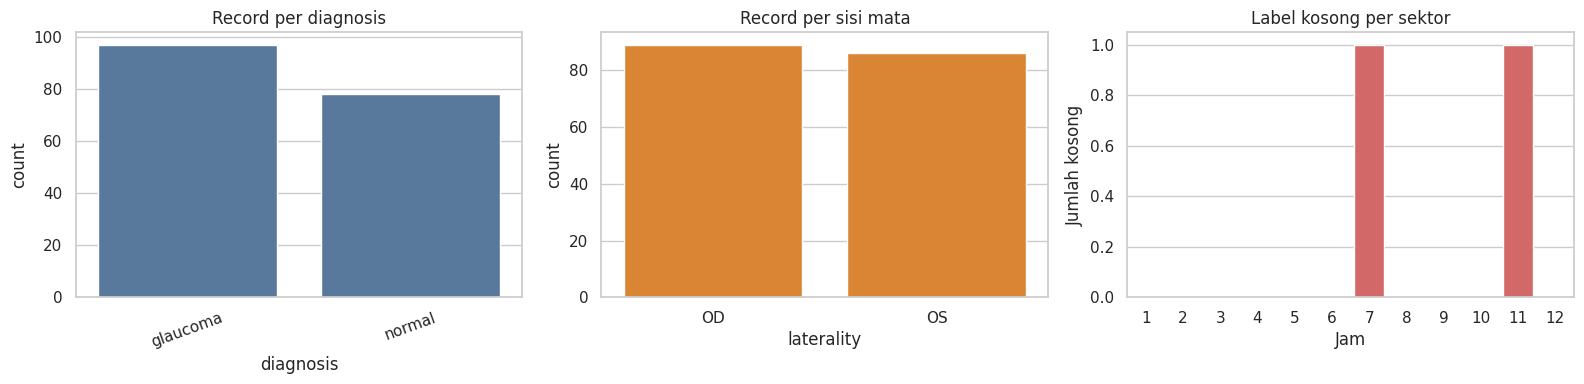

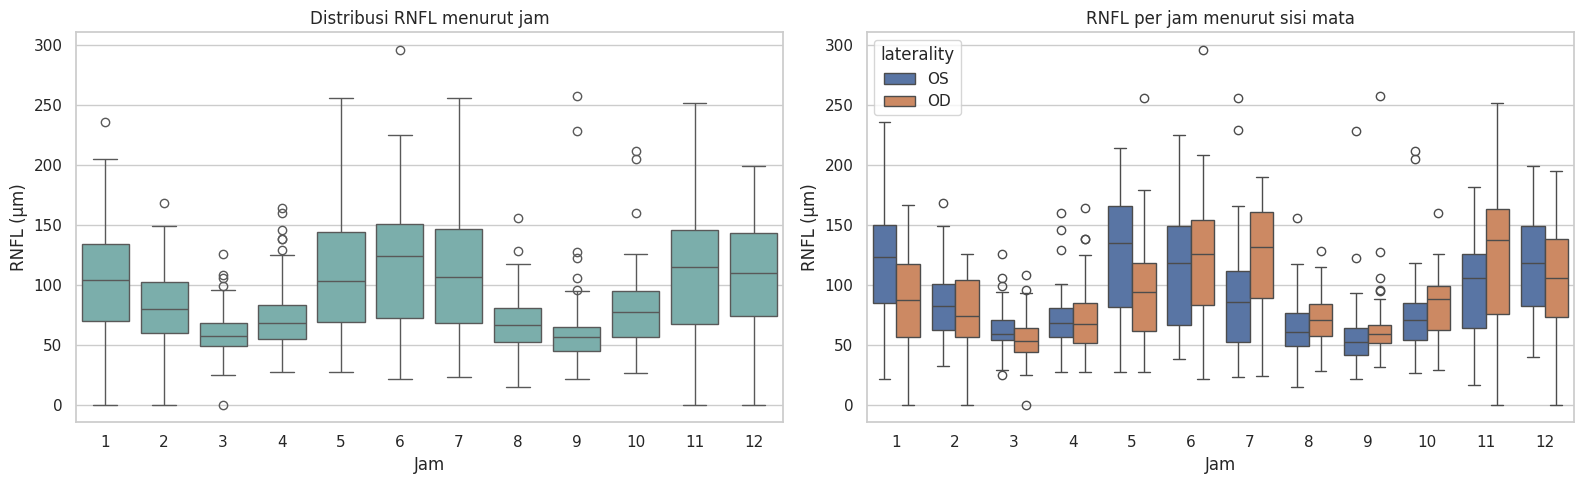

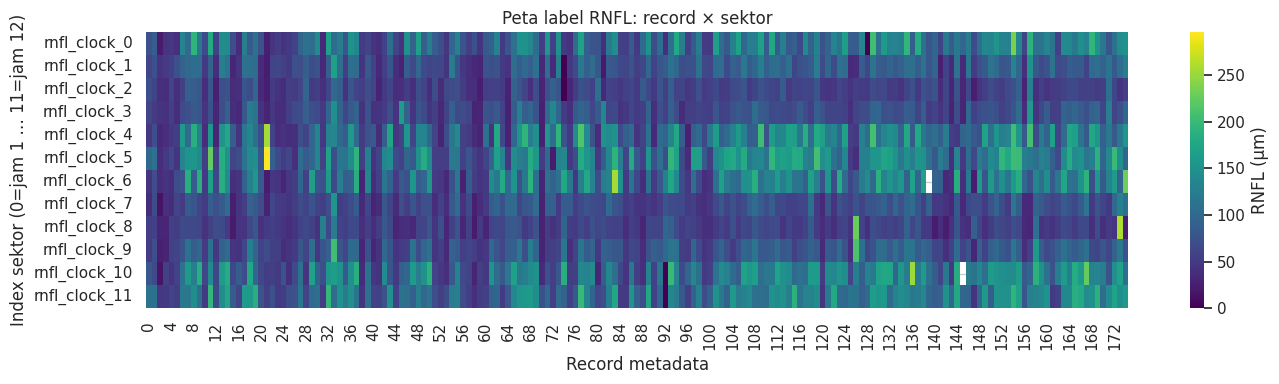

,sector,count,mean,std,min,25%,50%,75%,max
0,rnfl_clock_0,175.0,103.382857,43.372044,0.0,69.50,104.0,134.0,236.0
1,rnfl_clock_1,175.0,78.868571,28.132688,0.0,59.50,80.0,102.0,168.0
2,rnfl_clock_2,175.0,58.131429,17.687254,0.0,48.50,57.0,68.0,126.0
3,rnfl_clock_3,175.0,69.434286,24.578398,27.0,55.00,68.0,83.5,164.0
4,rnfl_clock_4,175.0,108.040000,48.887551,27.0,68.50,103.0,144.0,256.0
5,rnfl_clock_5,175.0,118.462857,48.680610,21.0,72.00,124.0,150.5,296.0
6,rnfl_clock_6,174.0,106.770115,48.523923,23.0,68.25,106.5,146.5,256.0
7,rnfl_clock_7,175.0,67.017143,21.925284,15.0,52.00,66.0,80.5,156.0
8,rnfl_clock_8,175.0,58.480000,26.129835,21.0,44.50,56.0,65.0,258.0
9,rnfl_clock_9,175.0,77.605714,28.459267,26.0,56.00,77.0,94.5,212.0


In [3]:
print("Jumlah record per diagnosis:")
display(df["diagnosis"].value_counts(dropna=False).rename_axis("diagnosis").to_frame("n"))
print("Record per laterality:")
display(df["laterality"].value_counts(dropna=False).rename_axis("laterality").to_frame("n"))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="diagnosis", order=df.diagnosis.value_counts().index, ax=ax[0], color="#4C78A8")
ax[0].set_title("Record per diagnosis"); ax[0].tick_params(axis="x", rotation=20)
sns.countplot(data=df, x="laterality", order=["OD","OS"], ax=ax[1], color="#F58518")
ax[1].set_title("Record per sisi mata")
miss = df[sector_cols].isna().sum()
sns.barplot(x=np.arange(12)+1, y=miss.values, ax=ax[2], color="#E45756")
ax[2].set_title("Label kosong per sektor"); ax[2].set_xlabel("Jam"); ax[2].set_ylabel("Jumlah kosong")
plt.tight_layout(); plt.show()

long_targets = df.melt(id_vars=["patient_id","laterality","diagnosis"], value_vars=sector_cols,
                       var_name="sector", value_name="rnfl_um").dropna(subset=["rnfl_um"])
long_targets["clock_hour"] = long_targets["sector"].str.extract(r"(\d+)$").astype(int) + 1
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=long_targets, x="clock_hour", y="rnfl_um", ax=ax[0], color="#72B7B2")
ax[0].set_title("Distribusi RNFL menurut jam"); ax[0].set_xlabel("Jam"); ax[0].set_ylabel("RNFL (µm)")
sns.boxplot(data=long_targets, x="clock_hour", y="rnfl_um", hue="laterality", ax=ax[1])
ax[1].set_title("RNFL per jam menurut sisi mata"); ax[1].set_xlabel("Jam"); ax[1].set_ylabel("RNFL (µm)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(df[sector_cols].T, cmap="viridis", cbar_kws={"label":"RNFL (µm)"}, ax=ax)
ax.set_title("Peta label RNFL: record × sektor")
ax.set_xlabel("Record metadata"); ax.set_ylabel("Index sektor (0=jam 1 … 11=jam 12)")
plt.tight_layout(); plt.show()

display(df[sector_cols].describe().T.rename_axis("sector").reset_index())
